<a href="https://colab.research.google.com/github/samuel1599gt/actividad2/blob/main/actividad4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Actividad 4 - Métodos de aprendizaje no supervisado

In [5]:

# Importación de librerías necesarias
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Modelo de aprendizaje no supervisado (K-Means para agrupamiento)
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Importar y conectar Google Drive
from google.colab import drive

drive.mount("/content/drive")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [6]:
# Leer archivo Excel desde Google Drive
datos = pd.read_excel('/content/drive/MyDrive/dataset_transporte_publico_120_registros.xlsx')

# Mostrar los primeros registros
print(datos.head())

   distancia_km  tiempo_minutos  combustible_litros
0          3.94              10               0.255
1          2.36               5               0.145
2          4.34              17               0.284
3          3.58              11               0.228
4          0.74               2               0.035


In [7]:
# Seleccionamos las tres variables de tu dataset
X = datos[["distancia_km", "tiempo_minutos", "combustible_litros"]]

# Normalizamos para que ninguna variable (como los minutos o el combustible)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

In [9]:
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

print("Datos originales (primeras 5 filas):")
display(X.head())
print("\nDatos normalizados (primeras 5 filas):")
display(X_scaled_df.head())

Datos originales (primeras 5 filas):


,distancia_km,tiempo_minutos,combustible_litros
0,3.94,10,0.255
1,2.36,5,0.145
2,4.34,17,0.284
3,3.58,11,0.228
4,0.74,2,0.035



Datos normalizados (primeras 5 filas):


,distancia_km,tiempo_minutos,combustible_litros
0,1.011218,0.398143,1.101932
1,-0.221594,-0.692660,-0.252776
2,1.323322,1.925267,1.459082
3,0.730324,0.616304,0.769413
4,-1.485616,-1.347141,-1.607484


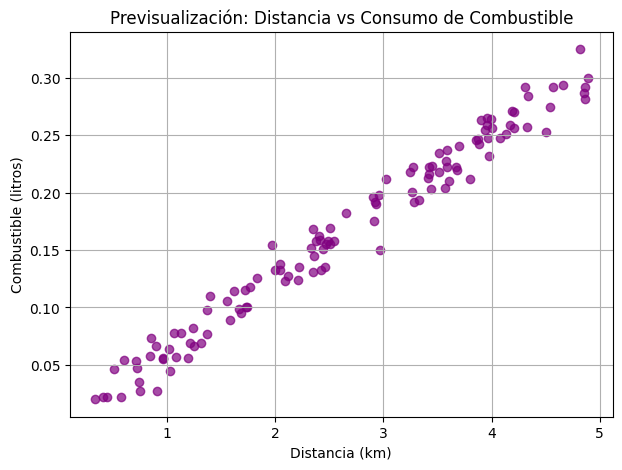

In [10]:
plt.figure(figsize=(7, 5))
plt.scatter(
    datos["distancia_km"],
    datos["combustible_litros"],
    color="purple",
    alpha=0.7,
)
plt.title("Previsualización: Distancia vs Consumo de Combustible")
plt.xlabel("Distancia (km)")
plt.ylabel("Combustible (litros)")
plt.grid(True)
plt.show()

In [11]:
# Definimos que queremos 3 grupos (clusters) y entrenamos con los datos normalizados (X_scaled)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans.fit(X_scaled)

# Guardamos las etiquetas de los grupos asignados a cada viaje en nuestro DataFrame original
datos["cluster"] = kmeans.labels_

In [13]:
# --- PASO 4: Mostrar métricas y resultados ---
print("=== MÉTRICAS DEL MODELO ===")
print(f"• Inercia total: {kmeans.inertia_:.4f}\n")

print("=== DISTRIBUCIÓN POR GRUPO ===")
print(datos["cluster"].value_counts().sort_index().to_string())

# Calculamos de nuevo los promedios para evitar el NameError
promedios_grupos = datos.groupby("cluster")[
    ["distancia_km", "tiempo_minutos", "combustible_litros"]
].mean()

print("\n=== PERFILES PROMEDIO POR GRUPO ===")
display(promedios_grupos.round(2))

=== MÉTRICAS DEL MODELO ===
• Inercia total: 58.6030

=== DISTRIBUCIÓN POR GRUPO ===
cluster
0    45
1    39
2    36

=== PERFILES PROMEDIO POR GRUPO ===


,distancia_km,tiempo_minutos,combustible_litros
cluster,,,
0,4.00,12.73,0.25
1,2.53,7.72,0.16
2,1.07,2.97,0.06


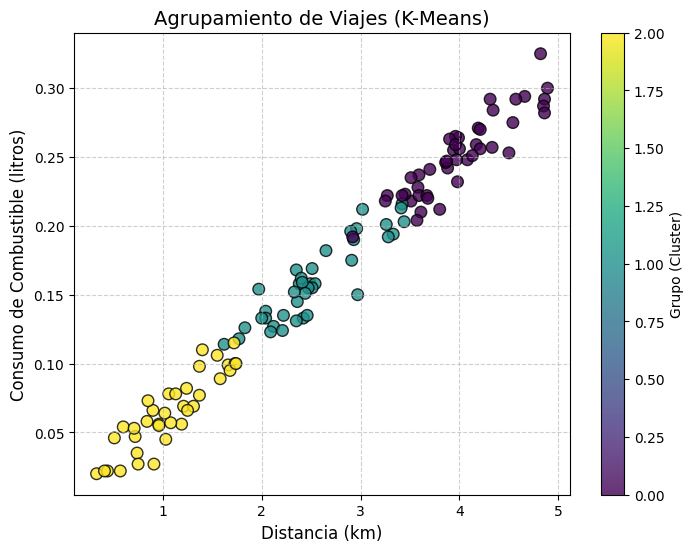

In [14]:
# --- PASO 5: Gráfica de los resultados de los Clusters ---
plt.figure(figsize=(8, 6))

# Creamos el gráfico de dispersión usando los clusters para dar color
scatter = plt.scatter(
    datos["distancia_km"],
    datos["combustible_litros"],
    c=datos["cluster"],
    cmap="viridis",
    s=70,
    alpha=0.8,
    edgecolor="k",
)

plt.title("Agrupamiento de Viajes (K-Means)", fontsize=14)
plt.xlabel("Distancia (km)", fontsize=12)
plt.ylabel("Consumo de Combustible (litros)", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)

# Agregamos una barra de color para identificar los clusters (0, 1 y 2)
plt.colorbar(scatter, label="Grupo (Cluster)")

plt.show()

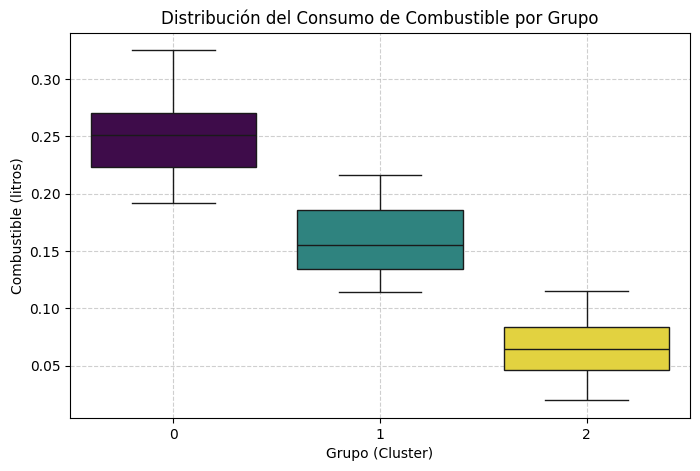

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.boxplot(
    x="cluster",
    y="combustible_litros",
    data=datos,
    palette="viridis",
    hue="cluster",
    legend=False,
)
plt.title("Distribución del Consumo de Combustible por Grupo")
plt.xlabel("Grupo (Cluster)")
plt.ylabel("Combustible (litros)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()